The following columns will be used to vectorization:

* title
* abstract
* index_terms

This means these are the features used for clustering and knn

# Utilities

In [1]:
save_data = True

## Libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import re, string, Levenshtein, joblib
import numpy as np

from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.feature_extraction.text import TfidfVectorizer

# Visualization
from wordcloud import WordCloud

## Functions

In [3]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text, save_figure):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    if save_figure:
        plt.savefig(f'../data/output/{save_figure}.pdf')
    plt.show()

# Load data

In [4]:
# Load data
data = pd.read_csv('../data/input/api/data.csv')
display(data.shape)
display(data.head())

(11517, 12)

,title,publisher,authors,content_type,abstract,html_url,publication_title,publication_year,citing_paper_count,citing_patent_count,download_count,index_terms
0,$\beta$-Ga2O3 in Power Electronics Converters:...,IEEE,{'authors': [{'affiliation': 'Electrical Energ...,Journals,"In this work, the possibility of using differe...",https://ieeexplore.ieee.org/document/10496151/,IEEE Open Journal of Power Electronics,2024.0,16,0,1737,Schottky diodes Costs Performance evaluation D...
1,(2N+1) Selective Harmonic Elimination-PWM for ...,IEEE,{'authors': [{'affiliation': 'Department of El...,Journals,The performance of modular multilevel converte...,https://ieeexplore.ieee.org/document/7849220/,IEEE Transactions on Power Electronics,2018.0,77,0,2341,Switches Harmonic analysis Pulse width modulat...
2,1-D Convolutional Neural Networks for Signal P...,IEEE,{'authors': [{'affiliation': 'Department of El...,Conferences,1D Convolutional Neural Networks (CNNs) have r...,https://ieeexplore.ieee.org/document/8682194/,ICASSP 2019 - 2019 IEEE International Conferen...,2019.0,257,0,10728,missing
3,1-MW Full-Bridge MMC for High-Current Low-Volt...,VDE,"{'authors': [{'full_name': 'Roland Unruh', 'au...",Conferences,A full-bridge modular multilevel converter (MM...,https://ieeexplore.ieee.org/document/9178138/,PCIM Europe digital days 2020; International E...,2020.0,0,0,397,missing
4,1-kV Input 1-MHz GaN Modular Multilevel LLC Co...,IEEE,{'authors': [{'affiliation': 'Aero-Power Sci-T...,Conferences,A modular multilevel LLC converter suitable fo...,https://ieeexplore.ieee.org/document/8721944/,2019 IEEE Applied Power Electronics Conference...,2019.0,3,0,770,Silicon carbide Inductors HEMTs MODFETs Stress...


# Choose features

These features will be used for vectorization

In [5]:
data.columns.tolist()

['title',
 'publisher',
 'authors',
 'content_type',
 'abstract',
 'html_url',
 'publication_title',
 'publication_year',
 'citing_paper_count',
 'citing_patent_count',
 'download_count',
 'index_terms']

In [6]:
# Feature columns
features = [
    'title',
    'abstract',
    'index_terms'
]

# Additional columns
additional_cols = [
    'publisher',
    'authors',
    'content_type',
    'html_url',
    'publication_title',
    'publication_year',
    'citing_paper_count',
    'citing_patent_count',
    'download_count',
    'insert_date'
]

In [7]:
# Features columns to lower case and remove special characters (let numbers)
for col in features:
    data[col] = data[col].str.lower()                                  # Lower case
    data[col] = data[col].str.replace(r'[^a-z0-9\s]', ' ', regex=True) # Remove spacial characters (let only letters, numbers and spaces)
    # data[col] = data[col].str.split(r'\s+')                          # Remove multiple spaces, convert to list (same as tokenization)
    data[col] = data[col].apply(word_tokenize)                         # Tokenization
    data[col] = data[col].apply(lambda x: ' '.join(x))                 # Convert back to string

data.head()

,title,publisher,authors,content_type,abstract,html_url,publication_title,publication_year,citing_paper_count,citing_patent_count,download_count,index_terms
0,beta ga2o3 in power electronics converters opp...,IEEE,{'authors': [{'affiliation': 'Electrical Energ...,Journals,in this work the possibility of using differen...,https://ieeexplore.ieee.org/document/10496151/,IEEE Open Journal of Power Electronics,2024.0,16,0,1737,schottky diodes costs performance evaluation d...
1,2n 1 selective harmonic elimination pwm for mo...,IEEE,{'authors': [{'affiliation': 'Department of El...,Journals,the performance of modular multilevel converte...,https://ieeexplore.ieee.org/document/7849220/,IEEE Transactions on Power Electronics,2018.0,77,0,2341,switches harmonic analysis pulse width modulat...
2,1 d convolutional neural networks for signal p...,IEEE,{'authors': [{'affiliation': 'Department of El...,Conferences,1d convolutional neural networks cnns have rec...,https://ieeexplore.ieee.org/document/8682194/,ICASSP 2019 - 2019 IEEE International Conferen...,2019.0,257,0,10728,missing
3,1 mw full bridge mmc for high current low volt...,VDE,"{'authors': [{'full_name': 'Roland Unruh', 'au...",Conferences,a full bridge modular multilevel converter mmc...,https://ieeexplore.ieee.org/document/9178138/,PCIM Europe digital days 2020; International E...,2020.0,0,0,397,missing
4,1 kv input 1 mhz gan modular multilevel llc co...,IEEE,{'authors': [{'affiliation': 'Aero-Power Sci-T...,Conferences,a modular multilevel llc converter suitable fo...,https://ieeexplore.ieee.org/document/8721944/,2019 IEEE Applied Power Electronics Conference...,2019.0,3,0,770,silicon carbide inductors hemts modfets stress...


In [8]:
# Remove duplicated rows by abstract, keeping the one with greater citing_paper_count

col = 'abstract'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data = data.loc[data.groupby(col)['citing_paper_count'].idxmax()].copy()

print(len(data), data.duplicated(subset=[col], keep=False).sum())

11517 92
11468 0


In [9]:
# Remove duplicated rows by title, keeping the one with longest abstract

# The Levenshtein distance between abstracts of rows with duplicated title
# is relatively low, meaning they are similar (manual inspection).

# Having that into account, the criterion to keep rows is the one with largest abstract.

col = 'title'

print(len(data), data.duplicated(subset=[col], keep=False).sum())

data['abstract_length'] = data['abstract'].apply(len)
data = data.loc[data.groupby(col)['abstract_length'].idxmax()].copy()
data.drop(columns=['abstract_length'], inplace=True)

print(len(data), data.duplicated(subset=[col], keep=False).sum())

11468 199
11368 0


In [10]:
# # Levenshtein distance analysis of abstract of rows with repeated title

# col = 'title'

# mask = data.duplicated(subset=[col], keep=False)
# data_rep = data[mask].sort_values(by=['title', 'citing_paper_count'], ascending=[True, False]).copy()
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: sorted(x.split(' ')))
# data_rep['abstract'] = data_rep['abstract'].apply(lambda x: ' '.join(x))
# data_rep

# n = len(data_rep)
# distance_matrix = np.zeros((n, n))

# for i in range(n):
#     for j in range(n):
#         if i != j:
#             distance_matrix[i, j] = Levenshtein.distance(data_rep.iloc[i]['abstract'], data_rep.iloc[j]['abstract'])

In [11]:
# # Identify data with suspicious title

# col = 'title'

# sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

In [12]:
# # Remove data with suspicious title

# suspicious_titles = \
# [
#  'booklet',
#  'contents',
#  'front cover',
#  'front matter',
#  'introduction',
#  'mmc based sst',
#  'keynote speech',
#  'control of mmcs',
#  'dc transmission',
#  'keynote speakers',
#  'table of content',
#  'best paper on rev',
#  'table of contents',
#  'meet the micro mmc',
#  'review of hvdc tap',
#  'main circuit design',
#  'wind energy systems',
#  'dynamics and control',
#  'proceedings contents',
#  'icrera 2018 tutorials',
#  'modeling and simulation',
#  'the closed loop revolution',
#  'design of capacitors in sst',
#  'hvdc systems in smart grids',
#  'control of statcoms a review',
#  'keynote speakers 4 abstracts',
#  'book reviews 7 books reviewed'
# ]

# mask = data['title'].isin(suspicious_titles)

# data.loc[mask, ['title', 'abstract']].sort_values(by=['abstract'])

In [13]:
# # Remove 
# mask = data['title'] == 'best paper on rev'
# data = data[~mask].copy()
data.shape

(11368, 12)

In [14]:
# # Remove data with suspicious abstract

# col = 'abstract'

# sorted(data[col].value_counts().sort_values().index.tolist(), key=len)

# # It seems that there isn't suspicious abstracts

In [15]:
# Filter abstracts using keywords

# Hexverter
m2c_keywords = 'hexverter'.split(' ')
m2c_keywords = '|'.join(m2c_keywords)
mask_m2c = data['abstract'].str.contains(m2c_keywords)

# M2C
m2c_keywords = 'mmc m2c modular multilevel converter'.split(' ')
m2c_keywords = '|'.join(m2c_keywords)
mask_m2c = data['abstract'].str.contains(m2c_keywords)

# M3C
m3c_keywords = 'mmmc m3c modular multilevel matrix converter'.split(' ')
m3c_keywords = '|'.join(m3c_keywords)
mask_m3c = data['abstract'].str.contains(m3c_keywords)

# # Control
# control_keywords = 'control controller'.split(' ')
# control_keywords = '|'.join(control_keywords)
# mask_control = data['abstract'].str.contains(control_keywords)

mask = (mask_m2c | mask_m3c)# & mask_control
lista_abstract = data.loc[mask, 'abstract'].unique().tolist()
lista_abstract = sorted(lista_abstract, key=len)
len(lista_abstract)

10247

In [16]:
# Remove abstracts which doesn't match keywords
data = data[data['abstract'].isin(lista_abstract)]
data.reset_index(drop=True, inplace=True)
data.shape

(10247, 12)

# EDA

Exploratory data analysis

In [17]:
data.columns.tolist()

['title',
 'publisher',
 'authors',
 'content_type',
 'abstract',
 'html_url',
 'publication_title',
 'publication_year',
 'citing_paper_count',
 'citing_patent_count',
 'download_count',
 'index_terms']

## title

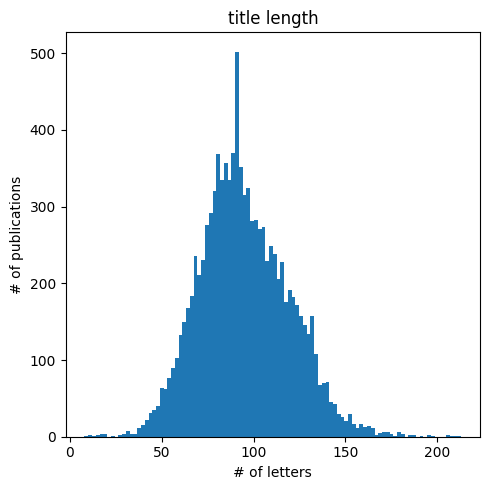

In [18]:
col = 'title'
plt.figure(figsize=(5, 5))
plt.hist(data[col].apply(len), bins=100)
plt.title(f'{col} length')
plt.ylabel('# of publications')
plt.xlabel('# of letters')
plt.tight_layout()
plt.show()

## publisher

In [19]:
col = 'publisher'
counts = data[col].value_counts()
display(counts)
percentages = counts / counts.sum() * 100
display(percentages)

publisher
IEEE      9426
IET        469
VDE        134
CSEE        94
SGEPRI      55
CPSS        28
PSPC        17
CMP         13
CES          9
TUP          1
Wiley        1
Name: count, dtype: int64

publisher
IEEE      91.987899
IET        4.576949
VDE        1.307700
CSEE       0.917342
SGEPRI     0.536742
CPSS       0.273251
PSPC       0.165902
CMP        0.126866
CES        0.087831
TUP        0.009759
Wiley      0.009759
Name: count, dtype: float64

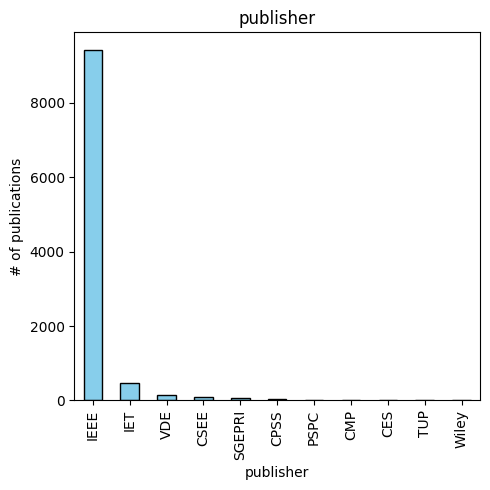

In [20]:
plt.figure(figsize=(5, 5))
counts.plot.bar(color='skyblue', edgecolor='black')
plt.title(f'{col}')
plt.ylabel(f'# of publications')
plt.xlabel(f'{col}')
plt.tight_layout()
plt.show()

## publication_title

In [21]:
col = 'publication_title'
max_results = 100
counts = data[col].value_counts().nlargest(max_results)
display(counts)
percentages = counts / counts.sum() * 100
display(percentages)

publication_title
IEEE Transactions on Power Electronics                                                                   827
IEEE Transactions on Power Delivery                                                                      443
IEEE Transactions on Industrial Electronics                                                              408
IEEE Journal of Emerging and Selected Topics in Power Electronics                                        322
IEEE Access                                                                                              286
                                                                                                        ... 
2021 IEEE 4th International Electrical and Energy Conference (CIEEC)                                      20
2023 IEEE 6th International Electrical and Energy Conference (CIEEC)                                      20
2022 IEEE 13th International Symposium on Power Electronics for Distributed Generation Systems (PEDG)     19
2

publication_title
IEEE Transactions on Power Electronics                                                                   14.182816
IEEE Transactions on Power Delivery                                                                       7.597325
IEEE Transactions on Industrial Electronics                                                               6.997085
IEEE Journal of Emerging and Selected Topics in Power Electronics                                         5.522209
IEEE Access                                                                                               4.904819
                                                                                                           ...    
2021 IEEE 4th International Electrical and Energy Conference (CIEEC)                                      0.342994
2023 IEEE 6th International Electrical and Energy Conference (CIEEC)                                      0.342994
2022 IEEE 13th International Symposium on Power Electronics fo

C:\Users\Pablo\AppData\Local\Temp\ipykernel_10584\3661612645.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


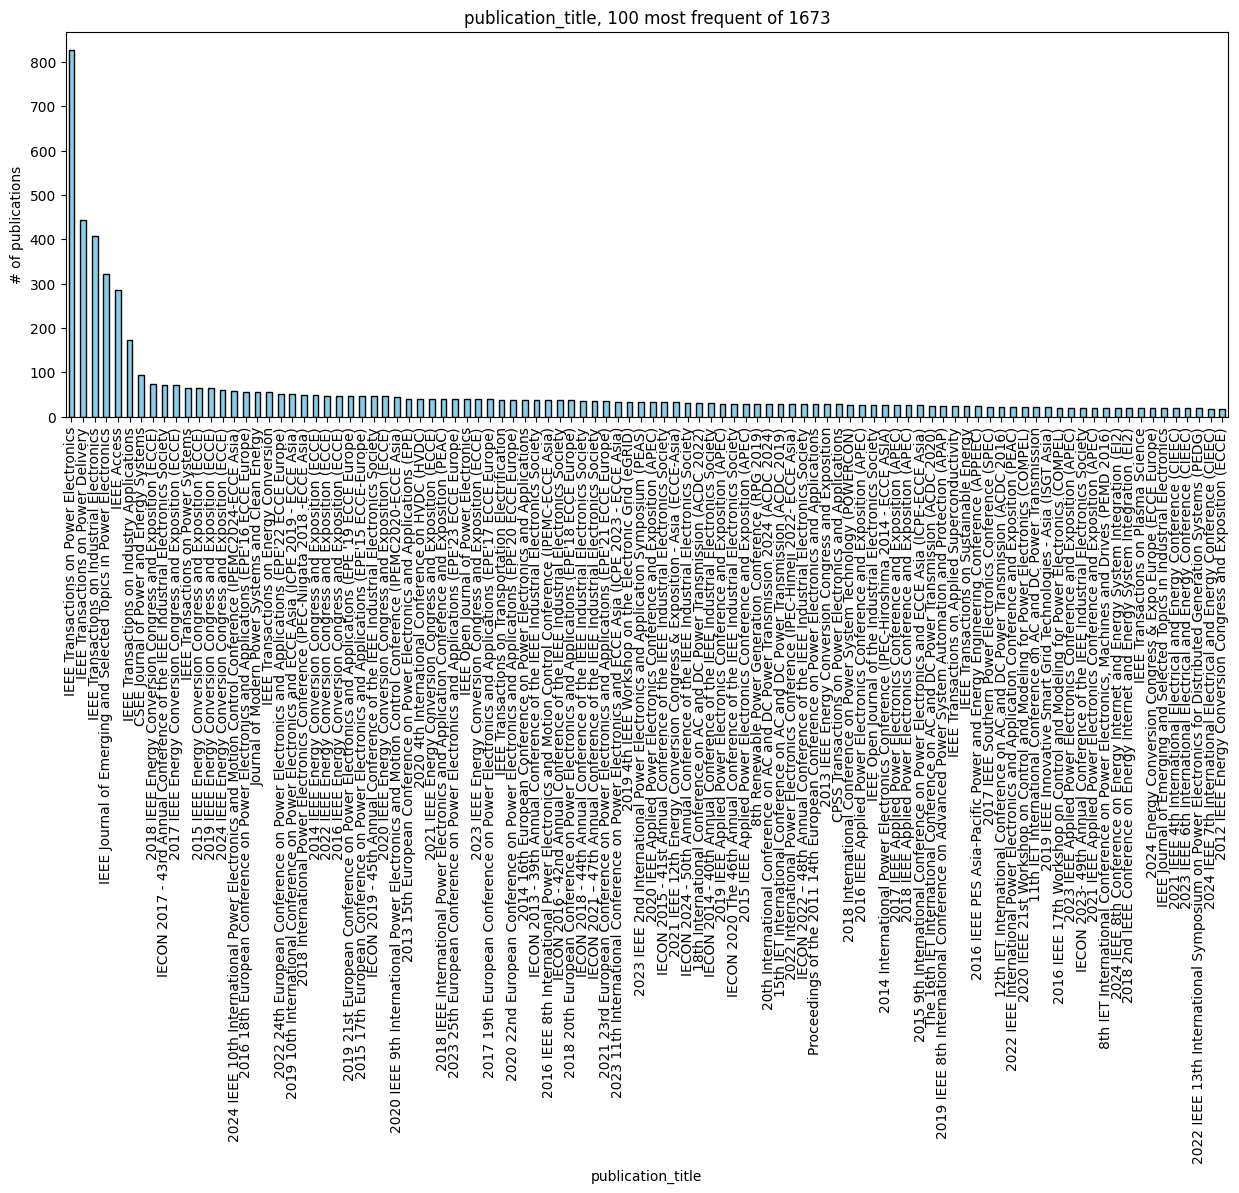

In [22]:
total_results = len(set(data[col]))
plt.figure(figsize=(15, 5))
counts.plot.bar(color='skyblue', edgecolor='black')
plt.title(f'{col}, {max_results} most frequent of {total_results}')
plt.ylabel(f'# of publications')
plt.xlabel(f'{col}')
plt.tight_layout()
plt.show()

## authors

This column deserve deeper analysis

## content_type

In [23]:
col = 'content_type'
counts = data[col].value_counts()
display(counts)
percentages = counts / counts.sum() * 100
display(percentages)

content_type
Conferences              7024
Journals                 3027
Early Access Articles     114
Books                      42
Magazines                  31
Standards                   9
Name: count, dtype: int64

content_type
Conferences              68.546892
Journals                 29.540353
Early Access Articles     1.112521
Books                     0.409876
Magazines                 0.302528
Standards                 0.087831
Name: count, dtype: float64

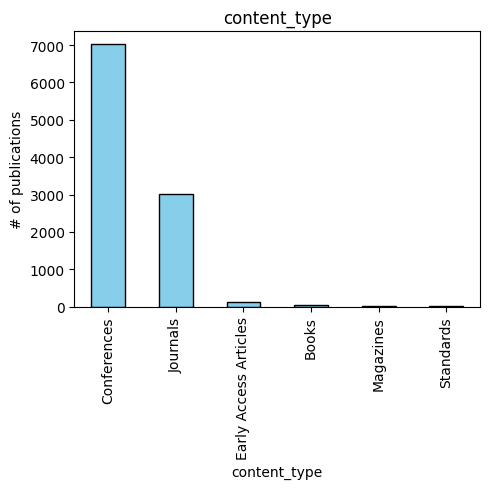

In [24]:
plt.figure(figsize=(5, 5))
counts.plot.bar(color='skyblue', edgecolor='black')
plt.title(f'{col}')
plt.ylabel(f'# of publications')
plt.xlabel(f'{col}')
plt.tight_layout()
plt.show()

## abstract

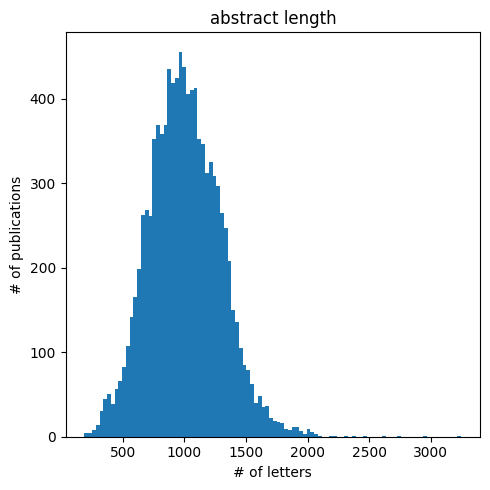

In [25]:
col = 'abstract'
plt.figure(figsize=(5, 5))
plt.hist(data[col].apply(len), bins=100)
plt.title(f'{col} length')
plt.ylabel('# of publications')
plt.xlabel('# of letters')
plt.tight_layout()
plt.show()

## publication_year

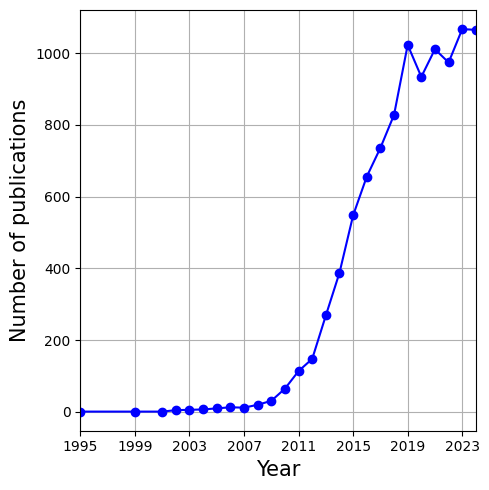

In [26]:
# publications per year

publication_years = data['publication_year'].astype(int).values
publication_years = pd.DataFrame(publication_years[publication_years < 2025])
publications_per_year = publication_years.value_counts().sort_index()

plt.figure(figsize=(5, 5))
plt.plot(publications_per_year.index.get_level_values(0), publications_per_year.values, marker='o', linestyle='-', color='b')

plt.xlabel('Year', size=15)
plt.xlim([publication_years.min().values[0], publication_years.max().values[0]])
plt.xticks(range(publication_years.min().values[0], publication_years.max().values[0], 4))
plt.ylabel('Number of publications', size=15)

plt.grid(True)

# plt.savefig('../data/output/publications_per_year.pdf')

plt.tight_layout()
plt.show()

## citing_paper_count

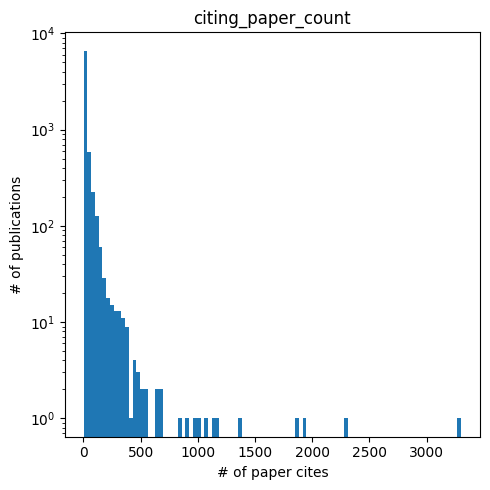

In [27]:
col = 'citing_paper_count'
plt.figure(figsize=(5, 5))
mask = data[col] > 0
plt.hist(data.loc[mask, col], log=True, bins=100)
plt.title(f'{col}')
plt.ylabel('# of publications')
plt.xlabel('# of paper cites')
plt.tight_layout()
plt.show()

In [ ]:
# Most cited papers
display(data[['title', 'abstract', 'publication_year']].sort_values(by=col, ascending=False).head(3))
data.sort_values(by=col, ascending=False).head(3)['html_url'].values

KeyError: 'citing_paper_count'

## Greater citing patent count

In [ ]:
['citing_patent_count',
 'download_count',
 'index_terms']

In [ ]:
col = 'citing_paper_count'
plt.figure(figsize=(5, 5))
mask = data[col] > 0
plt.hist(data.loc[mask, col], log=True, bins=100)
plt.title(f'{col}')
plt.ylabel('# of publications')
plt.xlabel('# of paper cites')
plt.tight_layout()
plt.show()

In [ ]:
column = 'citing_patent_count'
display(data.sort_values(by=column, ascending=False).head(3))
data.sort_values(by=column, ascending=False).head(3)['html_url'].values

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
1401,67,an innovative modular multilevel converter top...,voltage control network topology power generat...,20040614,this paper presents a new multilevel converter...,2260,https://ieeexplore.ieee.org/document/1304403/
5165,31,prototype of multiphase modular multilevel con...,prototypes voltage arm topology inverters cont...,20050425,a versatile prototype converter system of the ...,175,https://ieeexplore.ieee.org/document/1355234/
4725,28,on dynamics and voltage control of the modular...,voltage control capacitors leg capacitance cir...,20091006,this paper discusses the impact of modulation ...,180,https://ieeexplore.ieee.org/document/5278794/


array(['https://ieeexplore.ieee.org/document/1304403/',
       'https://ieeexplore.ieee.org/document/1355234/',
       'https://ieeexplore.ieee.org/document/5278794/'], dtype=object)

Oldest papers

In [ ]:
column = 'insert_date'
display(data.sort_values(by=column).head(3))
data.sort_values(by=column).head(3)['html_url'].values

,citing_patent_count,title,index_terms,insert_date,abstract,citing_paper_count,html_url
20,0,a 64 min single chip voice recorder player usi...,flash memory pulse modulation speech computer ...,20020807,a system on chip prototype implementing a full...,3,https://ieeexplore.ieee.org/document/910491/
2131,0,constant frequency current modulation algorith...,frequency modulation couplings hysteresis indu...,20030804,the present paper proposes an improved modulat...,18,https://ieeexplore.ieee.org/document/1218295/
2771,0,digitally implemented naturally sampled pwm su...,pulse width modulation pulse width modulation ...,20031110,for dynamic closed loop control of a multileve...,78,https://ieeexplore.ieee.org/document/1243690/


array(['https://ieeexplore.ieee.org/document/910491/',
       'https://ieeexplore.ieee.org/document/1218295/',
       'https://ieeexplore.ieee.org/document/1243690/'], dtype=object)

# Text preprocessing

In [ ]:
# Concatenate text columns

df = data[text_cols].copy()
df['text'] = df['title'] + ' ' + df['abstract'] + ' ' + df['index_terms']
df.head()

,title,index_terms,abstract,text
0,2 terminal hybrid hvdc cost effective alternat...,hvdc transmission voltage control circuit faul...,2 terminal hybrid hvdc consisting of a line co...,2 terminal hybrid hvdc cost effective alternat...
1,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,20 mw level offshore wind power converter base...
2,21 level csd based solar multilevel inverter f...,photovoltaic systems induction motor drives he...,as the demand for electricity increases renewa...,21 level csd based solar multilevel inverter f...
3,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,2n 1 selective harmonic elimination pwm for mo...
4,3 phase high gain pfc converter implementing s...,switches capacitors rectifiers harmonic analys...,in this paper a novel topology of three phase ...,3 phase high gain pfc converter implementing s...


In [ ]:
# Eliminate short words
min_word_len = 1
df['text'] = df['text'].str.split(' ').apply(lambda x: [word for word in x if len(word) > min_word_len]).apply(lambda x: ' '.join(x))
df['text']

0       terminal hybrid hvdc cost effective alternativ...
1       20 mw level offshore wind power converter base...
2       21 level csd based solar multilevel inverter f...
3       2n selective harmonic elimination pwm for modu...
4       phase high gain pfc converter implementing swi...
                              ...                        
6297    zero sequence voltage suppression control with...
6298    zero voltage switching double wing multilevel ...
6299    zpuc new configuration of single dc source for...
6300    zpuc mmc real time implementation with model p...
6301    zpuc9 mmc an increased voltage level modular m...
Name: text, Length: 6302, dtype: object

In [ ]:
# Apply text preprocessing
words2remove = []
df['text'] = df['text'].apply(lambda x: preprocess_text(x, words2remove))
df.head()

,title,index_terms,abstract,text
0,2 terminal hybrid hvdc cost effective alternat...,hvdc transmission voltage control circuit faul...,2 terminal hybrid hvdc consisting of a line co...,terminal hybrid hvdc cost effective alternativ...
1,20 mw level offshore wind power converter base...,switching converters multilevel converters cap...,with the development of offshore wind turbines...,mw level offshore wind power converter based s...
2,21 level csd based solar multilevel inverter f...,photovoltaic systems induction motor drives he...,as the demand for electricity increases renewa...,level csd based solar multilevel inverter fed ...
3,2n 1 selective harmonic elimination pwm for mo...,switches harmonic analysis pulse width modulat...,the performance of modular multilevel converte...,n selective harmonic elimination pwm modular m...
4,3 phase high gain pfc converter implementing s...,switches capacitors rectifiers harmonic analys...,in this paper a novel topology of three phase ...,phase high gain pfc converter implementing swi...


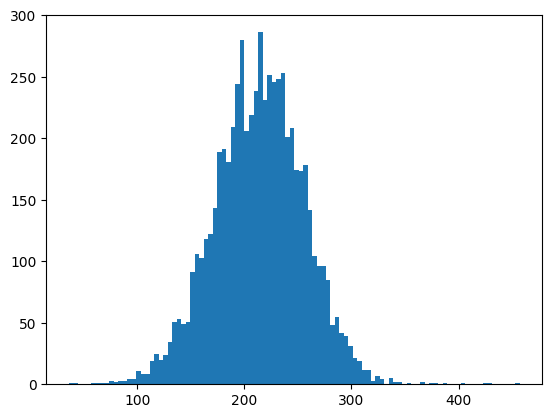

In [ ]:
plt.figure
plt.hist(df['text'].str.split().apply(len), 100)
plt.show()

# Word cloud

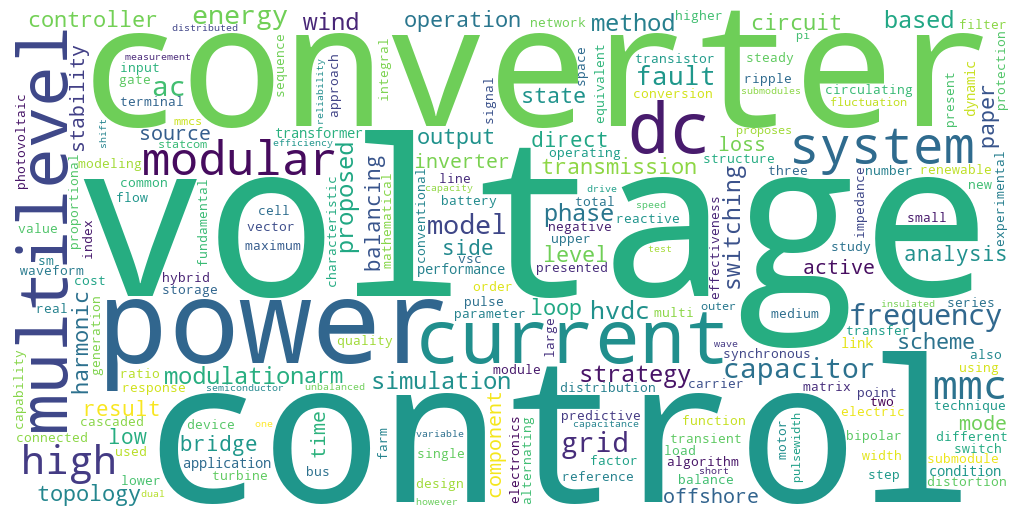

In [ ]:
text = ' '.join(df['text'].str.split(' ').explode())
word_cloud(text, save_figure='word_cloud_cluster')

# Vectorization

Tf idf

In [ ]:
df_vectorized = df.copy()

In [ ]:
vocabulary = ' '.join(df['text']).split(' ')
len(set(vocabulary))*11//10

13028

In [ ]:
# Extraer unigramas
vectorizer_unigrams = TfidfVectorizer(ngram_range=(1, 1))
X_unigrams = vectorizer_unigrams.fit_transform(df['text'])
unigram_vocab = set(vectorizer_unigrams.get_feature_names_out())

# # Extraer bigramas, limitando la cantidad
# max_features = len(unigram_vocab) * 1 // 10
# vectorizer_bigrams = TfidfVectorizer(ngram_range=(2, 2), max_features=max_features)
# X_bigrams = vectorizer_bigrams.fit_transform(df['text'])
# bigram_vocab = set(vectorizer_bigrams.get_feature_names_out())

# # Combinar vocabularios
# combined_vocab = list(unigram_vocab) + list(bigram_vocab)

combined_vocab = list(unigram_vocab)

# Vectorizador final usando el vocabulario combinado
vectorizer = TfidfVectorizer(vocabulary=combined_vocab)
X_vectorized = vectorizer.fit_transform(df['text'])
words = vectorizer.get_feature_names_out()

# DataFrame final
df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

In [ ]:
# vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=len(set(vocabulary))*15//10) # No sense to use ngrams, as the frequency of appearance decays rapidly
# X_vectorized = vectorizer.fit_transform(df['text'])
# words = vectorizer.get_feature_names_out()
# df_vectorized = pd.DataFrame(X_vectorized.toarray(), columns=words)

# Save vectorizer
joblib.dump(vectorizer, '../models/vectorizer.pkl')

['../models/vectorizer.pkl']

In [ ]:
df_vectorized.columns.str.split(' ').to_series().apply(len).value_counts()

1    11820
Name: count, dtype: int64

In [ ]:
df_vectorized.columns

Index(['contingent', 'opportunity', 'extent', 'invalid', 'history',
       'reconfigurability', 'lifespan', 'resemble', 'srg', 'sas',
       ...
       'sysil', 'thirteen', 'qimpcc', 'hccs', 'ssr', 'aurora', 'functionality',
       'isop', 'cascaded', 'changeableness'],
      dtype='object', length=11820)

In [ ]:
len(words), len(vocabulary)

(11820, 1348429)

In [ ]:
len(set(words)), len(set(vocabulary))

(11820, 11844)

In [ ]:
len(set(words) - set(vocabulary))

0

In [ ]:
len(set(vocabulary) - set(words))
set(vocabulary) - set(words)

{'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z'}

In [ ]:
# Vocabulary sorted by Tfidf score
df_vectorized.sum().sort_values()

satsdn              0.038527
mininet             0.038527
rustsat             0.038527
geostationary       0.038527
geosynchronous      0.038527
                     ...    
current           417.266026
power             489.844782
converter         500.926188
control           600.401489
voltage           735.680890
Length: 11820, dtype: float64

In [ ]:
# Vocabulary sorted by appearance frequency
(df_vectorized != 0).sum().sort_values()

mcbs             1
est              1
toplogy          1
ccoc             1
wheeling         1
              ... 
control       6115
voltage       6120
converter     6300
modular       6302
multilevel    6302
Length: 11820, dtype: int64

# DELETE NON RELATED

Using the indices of the KNN in the full corpus, extract the relevant publications

In [ ]:
if filter_by_knn_indexes:
    import json

    # Load the array from the JSON file
    with open('../data/output/knn_indices.json', 'r') as f:
        knn_indices = json.load(f)

    data = data.iloc[knn_indices].copy()
    df = df.iloc[knn_indices].copy()
    df_vectorized = df_vectorized.iloc[knn_indices].copy()

    data.reset_index(drop=True, inplace=True)
    df.reset_index(drop=True, inplace=True)
    df_vectorized.reset_index(drop=True, inplace=True)

In [ ]:
if save_data:
    # Save filtered data
    data.to_csv('../data/input/api/data_filtered.csv', index=False)

    # Save cleaned df
    df.to_csv('../data/input/api/data_cleaned.csv', index=False)

    # Save df_vectorized
    df_vectorized.to_csv('../data/output/df_vectorized.csv', index=False)